# HidroClima Ecuador · Proyecto Integrador Parte 2
**Asignatura:** Prácticas y Herramientas de Big Data · **Integrantes:** Zayo Vieria, Marlon Benavides, Martin Andrade

**Pregunta del proyecto:** ¿lloverán mañana 6 mm o más en la cuenca del río Paute, cantidad a partir de la cual empieza a subir el caudal que llega al embalse Mazar?

Contenido:
1. Datos
2. Limpieza
3. Definición de características
4. Gráficos representativos con groupby
5. Definición de la variable objetivo
6. Lista de posibles modelos

In [1]:
import pandas as pd

In [2]:
import requests

In [3]:
import time

## 1. Datos
Se usan dos fuentes abiertas de Open-Meteo, del 1 de enero de 2015 al 31 de diciembre de 2025:
- **API Historical Weather (reanálisis ERA5):** clima diario de 6 puntos de la cuenca del río Paute. Se eligieron puntos separados porque en ERA5 la lluvia tiene una resolución de unos 25 km y los puntos muy cercanos repiten la misma serie.
- **API Flood (modelo GloFAS):** caudal diario del río Paute en la zona del embalse Mazar.

En el primer avance se trabajaba con un solo punto por zona y dos zonas distintas. Ahora todos los datos son de la misma cuenca y cada día queda completo, sin filas descartadas.

In [4]:
url_clima = "https://archive-api.open-meteo.com/v1/archive"

In [5]:
variables = "temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,shortwave_radiation_sum,pressure_msl_mean,cloud_cover_mean"

In [6]:
puntos = {"Cajas": (-2.80, -79.20), "Chiquintad": (-2.78, -79.00), "Cuenca": (-2.90, -79.00), "Azogues": (-2.74, -78.85), "Gualaceo": (-2.89, -78.78), "Mazar": (-2.59, -78.63)}

In [7]:
def descargar(punto, lat, lon):
    params = {"latitude": lat, "longitude": lon, "start_date": "2015-01-01", "end_date": "2025-12-31", "daily": variables, "timezone": "America/Guayaquil"}
    for intento in range(5):
        respuesta = requests.get(url_clima, params=params, timeout=60)
        if respuesta.status_code != 429:
            break
        time.sleep(60)
    respuesta.raise_for_status()
    datos = pd.DataFrame(respuesta.json()["daily"])
    datos.insert(0, "punto", punto)
    return datos

La función define un tiempo máximo de espera y, si la API responde 429 por exceso de solicitudes, espera un minuto y vuelve a intentar.

In [8]:
clima = pd.concat([descargar(p, lat, lon) for p, (lat, lon) in puntos.items()], ignore_index=True)

In [9]:
params_caudal = {"latitude": -2.59, "longitude": -78.63, "start_date": "2015-01-01", "end_date": "2025-12-31", "daily": "river_discharge"}

In [10]:
caudal = pd.DataFrame(requests.get("https://flood-api.open-meteo.com/v1/flood", params=params_caudal, timeout=60).json()["daily"])

In [11]:
clima.shape

(24108, 12)

In [12]:
caudal.shape

(4018, 2)

Se obtuvieron 24.108 registros de clima, 4.018 días por cada uno de los 6 puntos, y 4.018 días de caudal.

In [13]:
clima.head()

,punto,time,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,shortwave_radiation_sum,pressure_msl_mean,cloud_cover_mean
0,Cajas,2015-01-01,13.1,6.8,11.2,11.2,13.0,89,5.5,13.68,1015.0,83
1,Cajas,2015-01-02,13.2,7.1,7.1,7.1,14.0,84,6.5,15.50,1014.5,83
2,Cajas,2015-01-03,13.2,7.2,5.2,5.2,9.0,82,6.2,16.68,1014.5,70
3,Cajas,2015-01-04,12.4,7.1,13.3,13.3,9.0,86,5.9,13.04,1015.7,75
4,Cajas,2015-01-05,12.1,6.3,1.9,1.9,9.0,83,5.0,15.38,1015.7,53


## 2. Limpieza

In [14]:
clima.isna().sum().sum()

np.int64(0)

In [15]:
caudal.isna().sum().sum()

np.int64(0)

In [16]:
clima.duplicated(["punto", "time"]).sum()

np.int64(0)

No hay valores faltantes en ninguna de las dos fuentes ni registros duplicados por punto y fecha.

In [17]:
(clima["precipitation_sum"] != clima["rain_sum"]).groupby(clima["punto"]).sum()

,0
punto,
Azogues,0
Cajas,697
Chiquintad,1
Cuenca,0
Gualaceo,0
Mazar,0


`rain_sum` solo cuenta la lluvia líquida. Difiere de `precipitation_sum` en 697 días en Cajas, el punto más alto, y en 1 día en Chiquintad. Se elimina `rain_sum` y se conserva la precipitación total, porque toda el agua que cae en la cuenca llega al río.

In [18]:
clima = clima.drop(columns="rain_sum")

In [19]:
clima = clima.rename(columns={"time": "fecha", "temperature_2m_max": "temp_max", "temperature_2m_min": "temp_min", "precipitation_sum": "precipitacion", "precipitation_hours": "horas_precipitacion", "relative_humidity_2m_mean": "humedad_media", "wind_speed_10m_max": "viento_max", "shortwave_radiation_sum": "radiacion", "pressure_msl_mean": "presion_media", "cloud_cover_mean": "nubosidad_media"})

In [20]:
caudal = caudal.rename(columns={"time": "fecha", "river_discharge": "caudal"})

In [21]:
clima["fecha"] = pd.to_datetime(clima["fecha"])

In [22]:
caudal["fecha"] = pd.to_datetime(caudal["fecha"])

Se renombran las columnas al español y la fecha pasa de texto a tipo fecha para poder unir las dos fuentes.

Se agrupan los 6 puntos por fecha para tener un solo dato diario de toda la cuenca. La lluvia de la cuenca es el promedio de los puntos y además se guarda la lluvia máxima de un punto. Luego se une el caudal por fecha.

In [23]:
cuenca = clima.groupby("fecha").agg(precipitacion=("precipitacion", "mean"), precip_max=("precipitacion", "max"), horas_precipitacion=("horas_precipitacion", "mean"), humedad_media=("humedad_media", "mean"), nubosidad_media=("nubosidad_media", "mean"), temp_max=("temp_max", "mean"), temp_min=("temp_min", "mean"), presion_media=("presion_media", "mean"), radiacion=("radiacion", "mean"), viento_max=("viento_max", "mean")).reset_index()

In [24]:
cuenca = cuenca.merge(caudal, on="fecha")

In [25]:
cuenca.shape

(4018, 12)

Validaciones: cada una debe devolver `True`.

In [26]:
(cuenca["fecha"].diff().dt.days.dropna() == 1).all()

np.True_

In [27]:
(cuenca["precipitacion"] >= 0).all()

np.True_

In [28]:
cuenca["humedad_media"].between(0, 100).all()

np.True_

In [29]:
(cuenca["caudal"] > 0).all()

np.True_

Todas las validaciones devuelven `True`: los días son consecutivos y no hay lluvia negativa, humedad fuera de rango ni caudal igual a cero. La tabla integrada tiene 4.018 días.

## 3. Definición de características

In [30]:
cuenca["mes"] = cuenca["fecha"].dt.month

In [31]:
cuenca["lluvia_7d"] = cuenca["precipitacion"].rolling(7).sum()

In [32]:
cuenca["caudal_sube"] = cuenca["caudal"].shift(-1) > cuenca["caudal"].shift(1)

| Característica | Qué representa | Por qué puede servir |
|---|---|---|
| `precipitacion` | Lluvia promedio de la cuenca hoy, en mm | Un día lluvioso suele seguir de otro lluvioso |
| `precip_max` | Lluvia del punto más lluvioso hoy | Detecta tormentas en una parte de la cuenca |
| `horas_precipitacion` | Horas con lluvia en el día | Lluvia continua indica un sistema que dura |
| `humedad_media` | Humedad relativa, en % | Aire húmedo favorece la lluvia |
| `nubosidad_media` | Porcentaje de cielo cubierto | Sin nubes no hay lluvia |
| `temp_max`, `temp_min` | Temperaturas en °C | Influyen en la evaporación y en la formación de nubes |
| `presion_media` | Presión al nivel del mar, en hPa | Cambios de presión anuncian cambios de tiempo |
| `radiacion` | Energía solar del día | Mucha radiación indica cielo despejado |
| `viento_max` | Viento máximo, en km/h | Movimiento de masas de aire |
| `caudal` | Caudal del río Paute, en m³/s | Resume la lluvia de los días anteriores |
| `lluvia_7d` | Lluvia acumulada de los últimos 7 días | Indica si la temporada está húmeda o seca |
| `mes` | Mes del año | La lluvia cambia por temporadas |

`caudal_sube` no es una característica del modelo. Es una columna auxiliar que vale `True` si el caudal de mañana es mayor que el de ayer y se usa para elegir el umbral de la variable objetivo.

In [33]:
cuenca[["precipitacion", "precip_max", "horas_precipitacion", "humedad_media", "caudal", "lluvia_7d"]].describe()

,precipitacion,precip_max,horas_precipitacion,humedad_media,caudal,lluvia_7d
count,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4012.000000
mean,5.215489,11.333773,10.435665,81.948689,216.122797,36.527401
std,4.352366,8.343468,5.106739,5.367753,117.334201,17.999325
min,0.000000,0.000000,0.000000,49.000000,61.090000,0.116667
25%,2.037500,5.300000,6.833333,79.500000,129.620000,23.083333
50%,4.133333,9.400000,10.500000,82.333333,191.090000,33.950000
75%,7.200000,15.200000,13.833333,85.166667,270.020000,46.800000
max,35.400000,63.300000,24.000000,94.666667,865.960000,134.916667


La lluvia promedio de la cuenca es de 5,2 mm diarios, pero la mediana es de 4,1 mm: hay muchos días de poca lluvia y pocos de lluvia fuerte, hasta 35,4 mm. En un solo punto se llegó a 63,3 mm. El caudal va de 61 a 866 m³/s, con un promedio de 216 m³/s.

## 4. Gráficos representativos con groupby

### Gráfico 1. Lluvia promedio por punto de la cuenca

<Axes: ylabel='punto'>

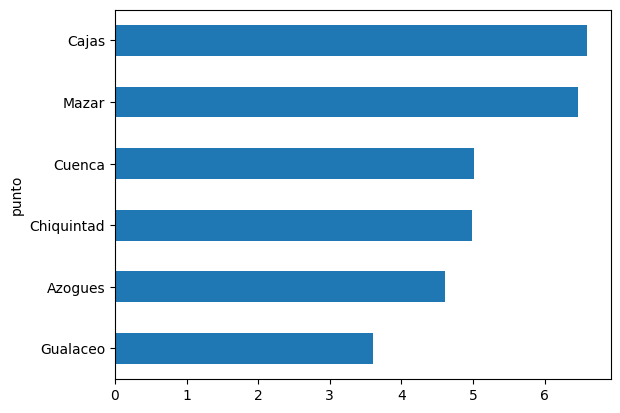

In [34]:
clima.groupby("punto")["precipitacion"].mean().sort_values().plot(kind="barh")

Cajas y Mazar son los puntos más lluviosos, con 6,6 y 6,5 mm diarios, y Gualaceo el más seco, con 3,6 mm. La lluvia cambia bastante dentro de la cuenca, por eso no basta con un solo punto.

### Gráfico 2. Lluvia promedio de la cuenca por mes

<Axes: xlabel='mes'>

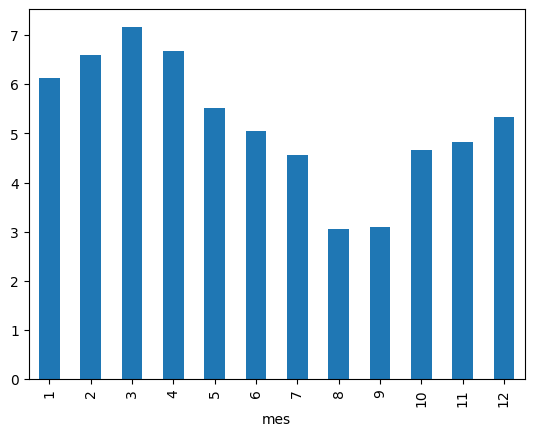

In [35]:
cuenca.groupby("mes")["precipitacion"].mean().plot(kind="bar")

La cuenca tiene una temporada lluviosa de enero a abril, con el máximo en marzo, 7,2 mm diarios. Agosto y septiembre son los meses más secos, con unos 3 mm.

### Gráfico 3. Caudal promedio por mes

<Axes: xlabel='mes'>

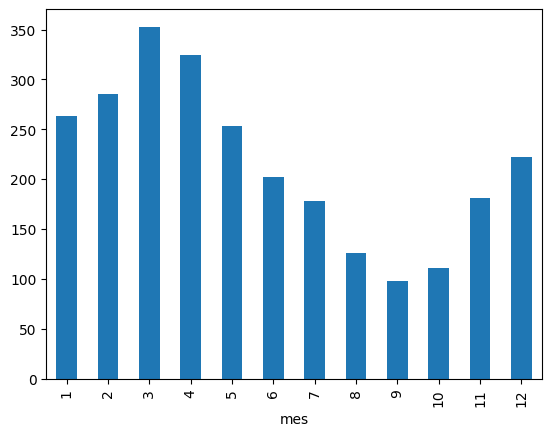

In [36]:
cuenca.groupby("mes")["caudal"].mean().plot(kind="bar")

El caudal sigue el mismo patrón que la lluvia: el máximo es en marzo, con 353 m³/s, y el mínimo en septiembre, con 98 m³/s. El río responde a la temporada de lluvias.

### Gráfico 4. Caudal promedio por año

<Axes: xlabel='fecha'>

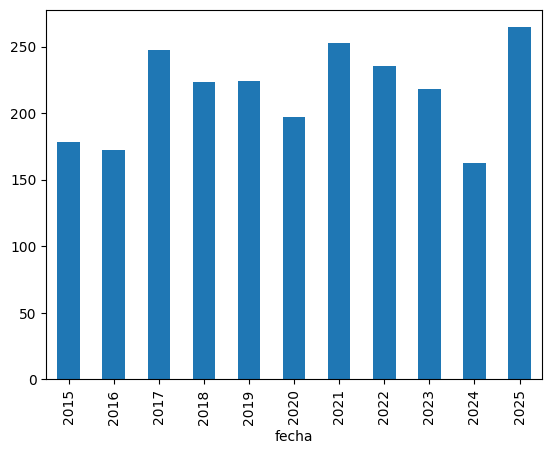

In [37]:
cuenca.groupby(cuenca["fecha"].dt.year)["caudal"].mean().plot(kind="bar")

2024 tiene el caudal promedio más bajo del periodo, 162 m³/s, lo que coincide con la sequía que dejó sin agua a la central Mazar y provocó los cortes de luz en Ecuador. 2025 tiene el más alto, 265 m³/s.

### Gráfico 5. Proporción de días en que sube el caudal según la lluvia del día

<Axes: xlabel='precipitacion'>

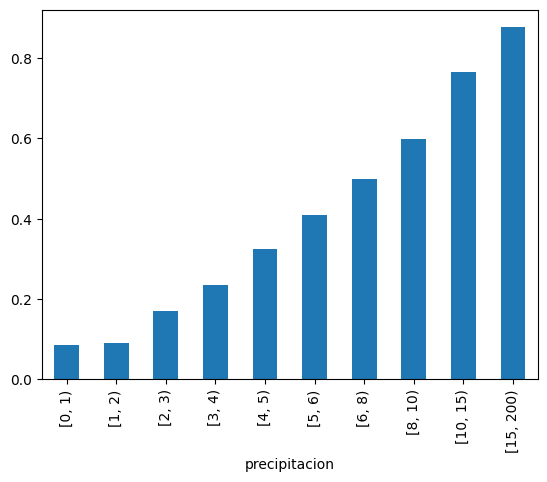

In [38]:
cuenca.groupby(pd.cut(cuenca["precipitacion"], [0, 1, 2, 3, 4, 5, 6, 8, 10, 15, 200], right=False), observed=True)["caudal_sube"].mean().plot(kind="bar")

In [39]:
cuenca.groupby(pd.cut(cuenca["precipitacion"], [0, 1, 2, 3, 4, 5, 6, 8, 10, 15, 200], right=False), observed=True)["caudal_sube"].agg(["mean", "count"])

,mean,count
precipitacion,,
"[0, 1)",0.084475,438
"[1, 2)",0.089888,534
"[2, 3)",0.169697,495
"[3, 4)",0.234568,486
"[4, 5)",0.324766,428
"[5, 6)",0.409524,315
"[6, 8)",0.497976,494
"[8, 10)",0.597561,328
"[10, 15)",0.765193,362


Con menos de 1 mm el caudal sube solo en el 8 % de los días. La proporción crece con la lluvia: 41 % entre 5 y 6 mm, 50 % entre 6 y 8 mm, 60 % entre 8 y 10 mm y 88 % con 15 mm o más. Desde 6 mm el caudal sube al menos en la mitad de los casos, por eso se toma como el umbral de lluvia importante para Mazar.

## 5. Definición de la variable objetivo

In [40]:
cuenca["precip_manana"] = cuenca["precipitacion"].shift(-1)

In [41]:
cuenca["lluvia_manana"] = (cuenca["precip_manana"] >= 6).astype(int)

In [42]:
cuenca = cuenca.drop(columns="caudal_sube").dropna()

In [43]:
cuenca.shape

(4011, 16)

**Variable objetivo:** `lluvia_manana`, que vale 1 si mañana caen 6 mm o más en promedio en la cuenca y 0 si no. `precip_manana` guarda los milímetros de mañana para el problema de regresión. Se eliminan las 7 filas incompletas que generan el desplazamiento y la lluvia de 7 días, y quedan 4.011 días.

In [44]:
cuenca["lluvia_manana"].value_counts()

,count
lluvia_manana,
0,2689
1,1322


Hay 1.322 días positivos y 2.689 negativos. El 33 % de los días tiene lluvia importante al día siguiente, así que las clases no están balanceadas.

### Gráfico 6. Proporción de días con lluvia importante al día siguiente por mes

<Axes: xlabel='mes'>

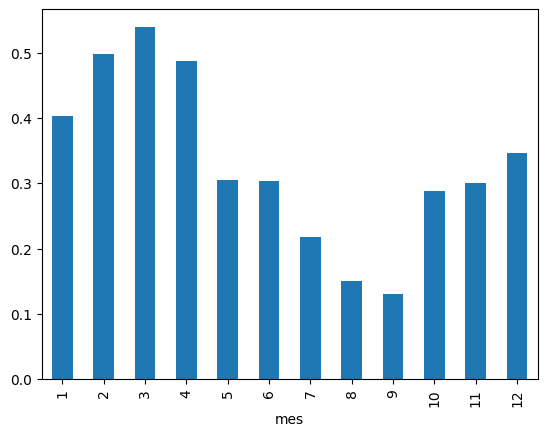

In [45]:
cuenca.groupby("mes")["lluvia_manana"].mean().plot(kind="bar")

La lluvia importante es mucho más frecuente de febrero a abril, en cerca de la mitad de los días, y muy rara en agosto y septiembre, en menos del 15 %. Por eso el mes es una característica útil.

### Gráfico 7. Humedad y nubosidad de hoy según si mañana hay lluvia importante

<Axes: xlabel='lluvia_manana'>

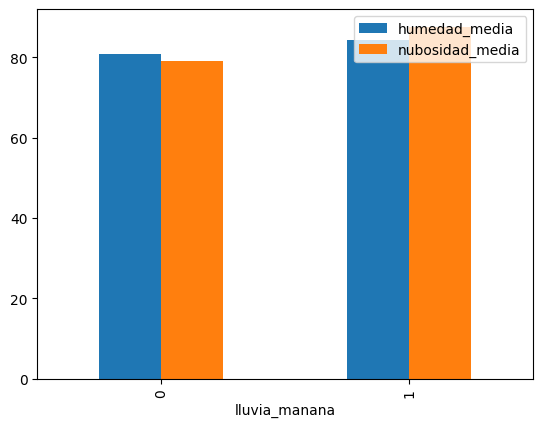

In [46]:
cuenca.groupby("lluvia_manana")[["humedad_media", "nubosidad_media"]].mean().plot(kind="bar")

Los días antes de una lluvia importante tienen más humedad, 84 % frente a 81 %, y más nubosidad, 88 % frente a 79 %. La diferencia no es muy grande, lo que muestra que predecir la lluvia de mañana no será sencillo.

In [47]:
cuenca.corr(numeric_only=True)["lluvia_manana"].sort_values()

,lluvia_manana
viento_max,-0.231300
mes,-0.165249
radiacion,-0.164035
presion_media,-0.127628
temp_max,-0.009386
caudal,0.244469
temp_min,0.271960
nubosidad_media,0.272035
lluvia_7d,0.287155
humedad_media,0.308246


Las características más relacionadas con el objetivo son la lluvia de hoy, 0,39, la lluvia máxima de un punto, las horas de lluvia y la humedad. El viento, la radiación y la presión tienen relación negativa. `precip_manana` aparece con 0,79 porque de ella sale el objetivo, por eso no se usa como entrada.

In [48]:
cuenca.to_csv("hidroclima_mazar_preparado.csv", index=False)

In [49]:
cuenca.to_parquet("hidroclima_mazar_preparado.parquet", index=False)

## 6. Lista de posibles modelos
Se plantean dos problemas con la misma información de entrada:

- **Clasificación**, problema principal: predecir `lluvia_manana` y la probabilidad de lluvia importante, expresada como baja, media o alta.
- **Regresión**, problema complementario: estimar `precip_manana` en milímetros.

**Métricas principales.** En clasificación, la métrica principal será el F1 de la clase positiva, que evalúa la decisión de sí o no sobre los días con lluvia importante y permite comparar directamente con la persistencia, que solo entrega una decisión y no una probabilidad. Como solo el 33 % de los días son positivos, el F1 es más informativo que la exactitud. Se reportarán también el recall de los días con lluvia importante y la matriz de confusión en porcentajes. El AUC se usará como métrica complementaria para evaluar la calidad de las probabilidades: mide qué tan bien el modelo separa los días con y sin lluvia importante, y un valor de 0,5 equivale a adivinar. En regresión se usará el MAE, el error medio en milímetros, porque la lluvia nunca es negativa y el MAE se interpreta directamente en mm.

**Referencia.** Todos los modelos se compararán con la persistencia: suponer que mañana pasará lo mismo que hoy. Un modelo útil debe superarla.

| Problema | Modelo | Por qué se considera |
|---|---|---|
| Clasificación | Regresión logística | Modelo base, sencillo de interpretar y entrega probabilidades |
| Clasificación | Árbol de decisión | Encuentra reglas como umbrales de humedad o de lluvia y se puede explicar |
| Clasificación | Random Forest | Combina muchos árboles y capta relaciones no lineales entre las variables |
| Clasificación | Gradient Boosting | Corrige los errores de árbol en árbol y suele funcionar bien con datos tabulares |
| Clasificación | K vecinos más cercanos | Compara el día de hoy con días parecidos del pasado |
| Regresión | Regresión lineal | Modelo base, aunque puede dar lluvia negativa |
| Regresión | Random Forest | Sus predicciones son promedios de días reales, por lo que nunca son negativas |
| Regresión | Gradient Boosting con pérdida Poisson | Pensado para cantidades que no pueden ser negativas, como la lluvia |

**Decisiones para el entrenamiento:**
- Se respetará el orden en el tiempo: 2015 a 2022 para entrenar y 2023 a 2025 para probar.
- Como solo el 33 % de los días son positivos, se probará balancear las clases y ajustar el umbral de decisión.
- No se usará ningún dato del día que se quiere predecir.

## Conclusión
- Los datos de la cuenca del Paute están completos: 4.011 días sin faltantes ni duplicados.
- Los gráficos muestran que la lluvia y el caudal siguen la misma temporada y que desde 6 mm de lluvia el caudal hacia Mazar sube al menos en la mitad de los días.
- La variable objetivo es `lluvia_manana` y las características de entrada son las 13 de la sección 3.
- Para el entrenamiento se compararán al menos los modelos de la lista, con el F1 de la clase positiva como métrica principal en clasificación, el AUC como complementaria, el MAE en regresión y la persistencia como referencia.